In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/batooljuaitem/titanic/gender_submission.csv
/kaggle/input/datasets/batooljuaitem/titanic/test.csv
/kaggle/input/datasets/batooljuaitem/titanic/train.csv


In [2]:
# Import Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load Dataset

df = pd.read_csv('/kaggle/input/datasets/batooljuaitem/titanic/train.csv')

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# Dataset Shape

print("Dataset Shape:", df.shape)

Dataset Shape: (891, 12)


In [5]:
# Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
# Statistical Description

df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
# Check Missing Values

print("Missing Values:")
print(df.isnull().sum())

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [8]:
# Drop Unnecessary Columns

df = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

print("Remaining Columns:")
print(df.columns)

Remaining Columns:
Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked'],
      dtype='object')


In [9]:
# Handle Missing Values

df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

print("Missing Values After Handling:")
print(df.isnull().sum())


Missing Values After Handling:
Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64


In [10]:
# Encode Categorical Features

df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})

df = pd.get_dummies(df, columns=['Embarked'], dtype=int)

print("Columns After Encoding:")
print(df.columns.tolist())

Columns After Encoding:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_C', 'Embarked_Q', 'Embarked_S']


In [11]:
# Separate Features and Target

X = df.drop('Survived', axis=1).values
y = df['Survived'].values

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (891, 9)
Target Shape: (891,)


In [12]:
# Split the Dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Shape: (712, 9)
Testing Shape: (179, 9)
Training Target Shape: (712,)
Testing Target Shape: (179,)


In [13]:
# Standardize the Features

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training Mean:", np.mean(X_train, axis=0))
print("Training Standard Deviation:", np.std(X_train, axis=0))

Training Mean: [-1.48445550e-16  2.78803198e-16  2.00779624e-16 -1.17259510e-16
 -8.57616100e-18  1.48576142e-15  1.50160783e-16  6.01266852e-16
  2.27969953e-16]
Training Standard Deviation: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [14]:
# Sigmoid Function

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [15]:
# Compute Loss

def compute_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

In [16]:
# Mini-Batch Gradient Descent

def train_mini_batch_gd(X, y, learning_rate=0.01, epochs=1000, batch_size=32):

    m, n = X.shape
    weights = np.zeros(n)
    bias = 0

    loss_history = []

    for epoch in range(epochs):

        indices = np.random.permutation(m)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, m, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            y_pred = sigmoid(np.dot(X_batch, weights) + bias)

            dw = np.dot(X_batch.T, (y_pred - y_batch)) / len(y_batch)
            db = np.mean(y_pred - y_batch)

            weights -= learning_rate * dw
            bias -= learning_rate * db

        predictions = sigmoid(np.dot(X, weights) + bias)
        loss = compute_loss(y, predictions)
        loss_history.append(loss)

    return weights, bias, loss_history

In [17]:
# Train Mini-Batch Gradient Descent Model

weights_mbgd, bias_mbgd, loss_history_mbgd = train_mini_batch_gd(
    X_train,
    y_train,
    learning_rate=0.01,
    epochs=1000,
    batch_size=32
)

print("Mini-Batch GD Training Completed!")

Mini-Batch GD Training Completed!


In [18]:
# Display Loss Progress

for i in range(0, len(loss_history_mbgd), 100):
    print(f"Epoch {i+1}, Loss: {loss_history_mbgd[i]:.4f}")

Epoch 1, Loss: 0.6621
Epoch 101, Loss: 0.4384
Epoch 201, Loss: 0.4365
Epoch 301, Loss: 0.4363
Epoch 401, Loss: 0.4363
Epoch 501, Loss: 0.4363
Epoch 601, Loss: 0.4363
Epoch 701, Loss: 0.4363
Epoch 801, Loss: 0.4363
Epoch 901, Loss: 0.4363


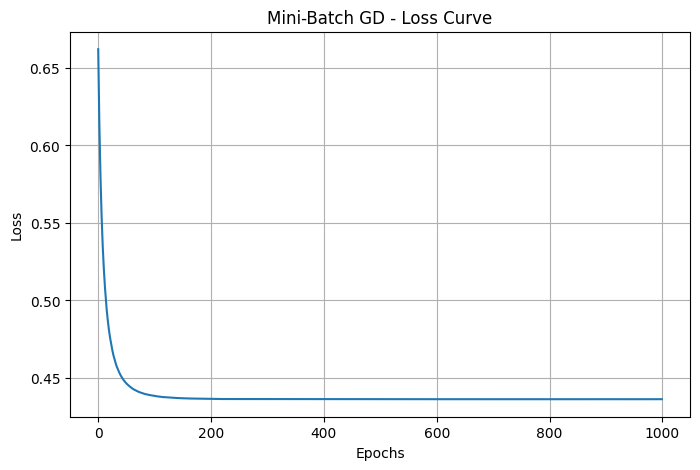

In [19]:
# Plot Loss Curve

plt.figure(figsize=(8, 5))
plt.plot(loss_history_mbgd)
plt.title("Mini-Batch GD - Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

In [20]:
# Make Predictions

y_prob_mbgd = sigmoid(np.dot(X_test, weights_mbgd) + bias_mbgd)
y_pred_mbgd = (y_prob_mbgd >= 0.5).astype(int)

print("Predictions:", y_pred_mbgd[:10])

Predictions: [0 0 0 0 1 0 1 0 0 0]


In [21]:
# Evaluate Model Performance

accuracy = accuracy_score(y_test, y_pred_mbgd)
precision = precision_score(y_test, y_pred_mbgd)
recall = recall_score(y_test, y_pred_mbgd)
f1 = f1_score(y_test, y_pred_mbgd)

print("Mini-Batch GD Results:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Mini-Batch GD Results:
Accuracy: 0.8100558659217877
Precision: 0.7966101694915254
Recall: 0.6811594202898551
F1 Score: 0.734375


In [22]:
# Confusion Matrix

cm_mbgd = confusion_matrix(y_test, y_pred_mbgd)

print("Confusion Matrix:")
print(cm_mbgd)

Confusion Matrix:
[[98 12]
 [22 47]]


In [23]:
# Mini-Batch Gradient Descent with Momentum

def train_mini_batch_gd_momentum(X, y, learning_rate=0.01, epochs=1000, batch_size=32, beta=0.9):

    m, n = X.shape
    weights = np.zeros(n)
    bias = 0

    v_w = np.zeros(n)
    v_b = 0

    loss_history = []

    for epoch in range(epochs):

        indices = np.random.permutation(m)
        X_shuffled = X[indices]
        y_shuffled = y[indices]

        for start in range(0, m, batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            y_pred = sigmoid(np.dot(X_batch, weights) + bias)

            dw = np.dot(X_batch.T, (y_pred - y_batch)) / len(y_batch)
            db = np.mean(y_pred - y_batch)

            v_w = beta * v_w + (1 - beta) * dw
            v_b = beta * v_b + (1 - beta) * db

            weights -= learning_rate * v_w
            bias -= learning_rate * v_b

        predictions = sigmoid(np.dot(X, weights) + bias)
        loss = compute_loss(y, predictions)
        loss_history.append(loss)

    return weights, bias, loss_history

In [24]:
# Train Mini-Batch GD with Momentum Model

weights_mbgd_momentum, bias_mbgd_momentum, loss_history_mbgd_momentum = train_mini_batch_gd_momentum(
    X_train,
    y_train,
    learning_rate=0.01,
    epochs=1000,
    batch_size=32,
    beta=0.9
)

print("Mini-Batch GD with Momentum Training Completed!")

Mini-Batch GD with Momentum Training Completed!


In [25]:
# Display Loss Progress

for i in range(0, len(loss_history_mbgd_momentum), 100):
    print(f"Epoch {i+1}, Loss: {loss_history_mbgd_momentum[i]:.4f}")

Epoch 1, Loss: 0.6716
Epoch 101, Loss: 0.4383
Epoch 201, Loss: 0.4364
Epoch 301, Loss: 0.4363
Epoch 401, Loss: 0.4363
Epoch 501, Loss: 0.4363
Epoch 601, Loss: 0.4363
Epoch 701, Loss: 0.4363
Epoch 801, Loss: 0.4363
Epoch 901, Loss: 0.4363


In [26]:
print("Mini-Batch GD Loss:", loss_history_mbgd[-1])
print("Mini-Batch GD with Momentum Loss:", loss_history_mbgd_momentum[-1])

Mini-Batch GD Loss: 0.43629256219833157
Mini-Batch GD with Momentum Loss: 0.436278071312459


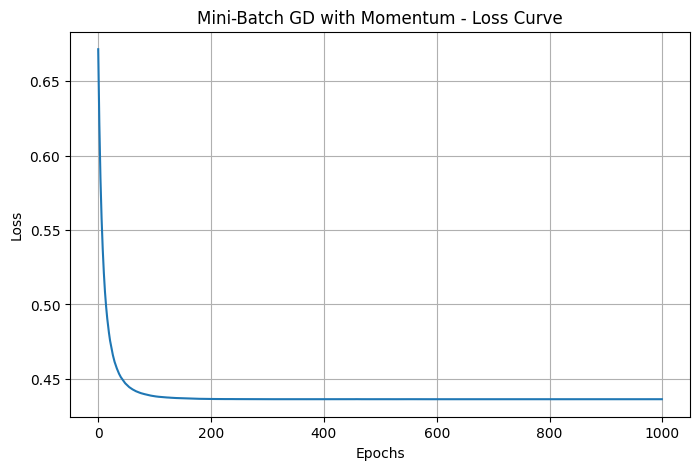

In [27]:
# Plot Loss Curve

plt.figure(figsize=(8, 5))
plt.plot(loss_history_mbgd_momentum)

plt.title("Mini-Batch GD with Momentum - Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

In [28]:
# Make Predictions

y_prob_mbgd_momentum = sigmoid(
    np.dot(X_test, weights_mbgd_momentum) + bias_mbgd_momentum
)

y_pred_mbgd_momentum = (y_prob_mbgd_momentum >= 0.5).astype(int)

print("Predictions:", y_pred_mbgd_momentum[:10])

Predictions: [0 0 0 0 1 0 1 0 0 0]


In [29]:
# Evaluate Model Performance

accuracy = accuracy_score(y_test, y_pred_mbgd_momentum)
precision = precision_score(y_test, y_pred_mbgd_momentum)
recall = recall_score(y_test, y_pred_mbgd_momentum)
f1 = f1_score(y_test, y_pred_mbgd_momentum)

print("Mini-Batch GD with Momentum Results:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Mini-Batch GD with Momentum Results:
Accuracy: 0.8100558659217877
Precision: 0.7966101694915254
Recall: 0.6811594202898551
F1 Score: 0.734375


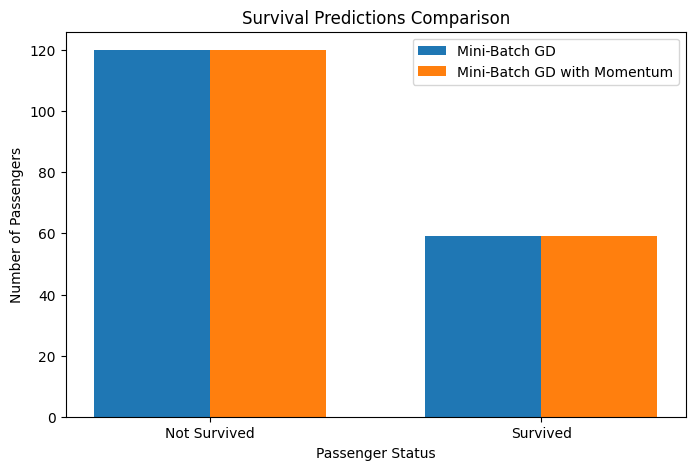

In [30]:
# Compare Survival Predictions: Mini-Batch GD vs Mini-Batch GD with Momentum

mbgd_not_survived = np.sum(y_pred_mbgd == 0)
mbgd_survived = np.sum(y_pred_mbgd == 1)

momentum_not_survived = np.sum(y_pred_mbgd_momentum == 0)
momentum_survived = np.sum(y_pred_mbgd_momentum == 1)

labels = ['Not Survived', 'Survived']

mbgd_counts = [mbgd_not_survived, mbgd_survived]
momentum_counts = [momentum_not_survived, momentum_survived]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width/2, mbgd_counts, width, label='Mini-Batch GD')
plt.bar(x + width/2, momentum_counts, width, label='Mini-Batch GD with Momentum')

plt.xlabel('Passenger Status')
plt.ylabel('Number of Passengers')
plt.title('Survival Predictions Comparison')
plt.xticks(x, labels)
plt.legend()
plt.show()

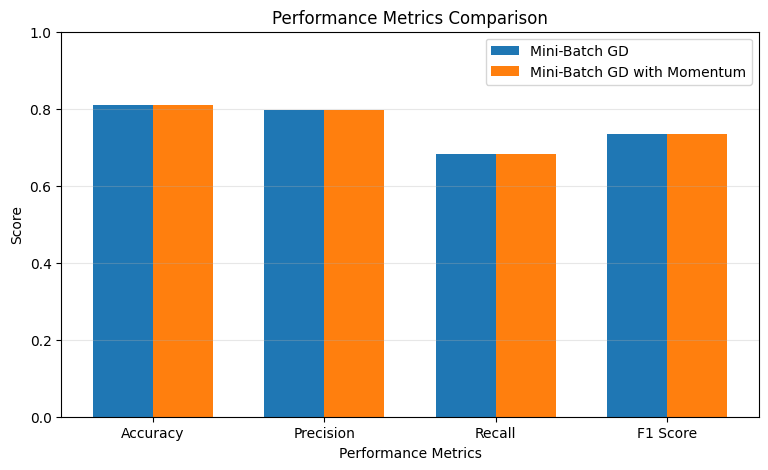

In [31]:
# Performance Metrics Comparison

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

mbgd_scores = [
    accuracy_score(y_test, y_pred_mbgd),
    precision_score(y_test, y_pred_mbgd),
    recall_score(y_test, y_pred_mbgd),
    f1_score(y_test, y_pred_mbgd)
]

momentum_scores = [
    accuracy_score(y_test, y_pred_mbgd_momentum),
    precision_score(y_test, y_pred_mbgd_momentum),
    recall_score(y_test, y_pred_mbgd_momentum),
    f1_score(y_test, y_pred_mbgd_momentum)
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, mbgd_scores, width, label='Mini-Batch GD')
plt.bar(x + width/2, momentum_scores, width, label='Mini-Batch GD with Momentum')

plt.xlabel('Performance Metrics')
plt.ylabel('Score')
plt.title('Performance Metrics Comparison')
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.show()

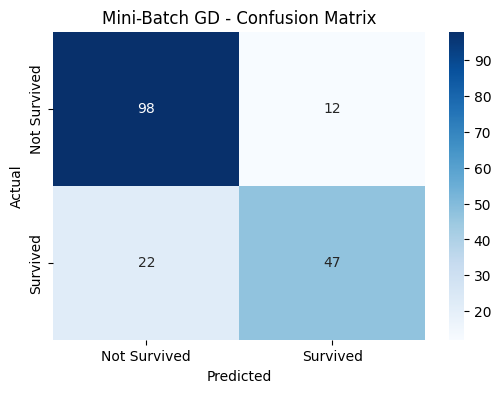

In [32]:
# Confusion Matrix - Mini-Batch GD

cm_mbgd = confusion_matrix(y_test, y_pred_mbgd)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_mbgd,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Mini-Batch GD - Confusion Matrix')
plt.show()

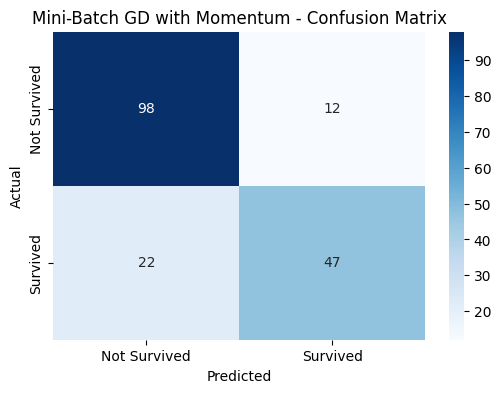

In [33]:
# Confusion Matrix - Mini-Batch GD with Momentum

cm_mbgd_momentum = confusion_matrix(y_test, y_pred_mbgd_momentum)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_mbgd_momentum,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Survived', 'Survived'],
    yticklabels=['Not Survived', 'Survived']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Mini-Batch GD with Momentum - Confusion Matrix')
plt.show()

In [34]:
# Compare Predictions

print("Identical Predictions:",
      np.array_equal(y_pred_mbgd, y_pred_mbgd_momentum))

print("Different Predictions:",
      np.sum(y_pred_mbgd != y_pred_mbgd_momentum))

Identical Predictions: True
Different Predictions: 0
